### DSAI3204 IoT Application Development: Project

#### Maryam Mahaboob
#### Sensors: VOC, temperature & humidity (Arduino MKR IoT Carrier)

## Summary

**Goal:** auto-ARIMA for each sensor (temperature, humidity, VOC), with an ADF test, a 100-minute forecast, a backtest on the last 100 minutes, and residual plots.

**Data:** now reads `../data/sensors_1min.csv` (21,016 rows, 3–17 June). **The saved outputs come from the original run on the old `processed_data.csv`** (7,005 rows, 3–7 June), whose humidity column was misaligned in time. Re-running will give different numbers.

**Split:** hold out the last 100 minutes. **Horizon:** 100 minutes.

**Key result (saved output) vs baselines:**

| Sensor | auto-ARIMA order | RMSE / MAE | Best simple baseline (RMSE / MAE) |
|---|---|---|---|
| Temperature | (0,1,1) | 0.2636 / 0.2337 | train mean 0.1983 / 0.1676 |
| Humidity | (2,1,3) | 0.3024 / 0.2575 | last value 0.2990 / 0.2456 |
| VOC | (1,1,2) | 0.0440 / 0.0314 | train mean 0.0358 / 0.0296 (last value 0.0647) |

The baselines were computed later, during a review of the project. ARIMA does not beat the best simple baseline for any sensor; for VOC it only beats "repeat the last value".

**Caveats**
- The ARIMA order is chosen on the full series, including the 100 test minutes (mild leakage).
- In the saved run the humidity series is misaligned in time (old `processed_data.csv` bug), so the humidity result is not meaningful.
- One backtest window of 100 minutes is a very small test.
- `mean_squared_error(..., squared=False)` needs scikit-learn < 1.6.


##### CONTENTS: humidity, temp & voc Forecasting Trends

In [1]:
# ==============================
# Data Handling and Visualization
# ==============================
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ==============================
# Automated ARIMA Model Selection
# ==============================
from pmdarima import auto_arima

# ==============================
# Model Evaluation Metrics
# ==============================
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

# ==============================
# Time Series Analysis Tools
# ==============================
from statsmodels.tsa.stattools import adfuller

FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

In [2]:
# --- Load and Prepare Data ---
df = pd.read_csv('../data/sensors_1min.csv')
df['time'] = pd.to_datetime(df['time'], format="ISO8601", utc=True)
df.set_index('time', inplace=True)

In [3]:
# Regular 1-minute grid: the 2 empty minutes become NaN here and are filled by time interpolation below
df = df.resample('1min').mean()

summary_rows = []


def forecast_series(series, label='Variable', n_periods=100):
    # Regular 1-minute grid (interpolate the empty minutes instead of dropping them, so the index keeps its frequency)
    series = series.asfreq('1min').interpolate(method='time')

    # --- Backtest split: hold out the last n_periods minutes ---
    train, test = series.iloc[:-n_periods], series.iloc[-n_periods:]
    print(f"\nLeakage check for {label}: last train {train.index[-1]} < first test {test.index[0]}: {train.index[-1] < test.index[0]}")

    # --- Stationarity Check: Augmented Dickey-Fuller Test (training part) ---
    result = adfuller(train)
    print(f"\nADF Test for {label}")
    print(f"ADF Statistic: {result[0]}")
    print(f"p-value: {result[1]}")
    for key, value in result[4].items():
        print(f"Critical Value {key}: {value}")

    # --- Fit Auto ARIMA Model on the training part only (order chosen without the test minutes) ---
    print(f"\nFitting Auto ARIMA for {label}...")
    model = auto_arima(train, seasonal=False, trace=True,
                       error_action='ignore', suppress_warnings=True)
    print(model.summary())

    # --- Backtest on the last n_periods minutes, next to naive baselines ---
    pred = np.asarray(model.predict(n_periods=n_periods))
    candidates = {
        f"auto-ARIMA{model.order}": pred,
        "Baseline: train mean": np.full(n_periods, train.mean()),
        "Baseline: last value (persistence)": np.full(n_periods, train.iloc[-1]),
    }
    rows = []
    for name, p in candidates.items():
        rows.append((name, root_mean_squared_error(test, p), mean_absolute_error(test, p)))
    table = pd.DataFrame(rows, columns=["model", "RMSE", "MAE"]).set_index("model")
    print(f"\nBacktest for {label} (last {n_periods} minutes):")
    print(table.round(4).to_string())
    arima_name = table.index[0]
    best_base = table.iloc[1:]["RMSE"].idxmin()
    beats = table.loc[arima_name, "RMSE"] < table.loc[best_base, "RMSE"]
    print(f"Best baseline: {best_base}. auto-ARIMA beats it: {beats}")
    summary_rows.append({
        "sensor": label, "order": str(model.order),
        "ARIMA RMSE": table.loc[arima_name, "RMSE"], "ARIMA MAE": table.loc[arima_name, "MAE"],
        "best baseline": best_base.replace("Baseline: ", ""),
        "baseline RMSE": table.loc[best_base, "RMSE"], "baseline MAE": table.loc[best_base, "MAE"],
    })

    plt.figure(figsize=(15, 4))
    plt.plot(series[-300:], label=f'Observed {label}', color='blue')
    plt.plot(test.index, pred, label=f'auto-ARIMA{model.order} backtest', color='red')
    plt.plot(test.index, candidates["Baseline: train mean"], label='Train mean', linestyle='--')
    plt.plot(test.index, candidates["Baseline: last value (persistence)"], label='Last value', linestyle=':')
    plt.title(f"{label} - Backtest on the last {n_periods} minutes")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"arima_{label.lower()}_backtest.png", bbox_inches='tight')
    plt.show()

    # --- Forecast Future Points: refit the same order on the full series ---
    model.fit(series)
    forecast, conf_int = model.predict(n_periods=n_periods, return_conf_int=True)
    conf_int = np.asarray(conf_int)
    last_index = series.index[-1]
    forecast_index = pd.date_range(start=last_index + pd.Timedelta(minutes=1),
                                   periods=n_periods, freq='1min')
    # np.asarray drops the model's own index, so the values are not re-aligned to NaN
    forecast_series = pd.Series(np.asarray(forecast), index=forecast_index)
    print(f"Forecast values that are NaN: {int(forecast_series.isna().sum())} of {n_periods}")

    # --- Visualization ---

    # 1. Full Forecast Plot (Last 500 points + forecast)
    plt.figure(figsize=(15, 6))
    plt.plot(series[-500:], label=f'Observed {label}', color='blue')
    plt.plot(forecast_series, label=f'Forecast {label}', color='red')
    plt.fill_between(forecast_index, conf_int[:, 0], conf_int[:, 1], color='pink', alpha=0.3)
    plt.title(f"{label} Forecast using ARIMA")
    plt.xlabel("Time")
    plt.ylabel(label)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"arima_{label.lower()}_forecast.png", bbox_inches='tight')
    plt.show()

    # 2. Zoomed-in Plot: Recent Actual vs Forecast
    plt.figure(figsize=(15, 4))
    plt.plot(series[-200:], label='Recent Actual')
    plt.axvline(series.index[-1], color='black', linestyle='--', label='Forecast Start')
    plt.plot(forecast_series, label='Forecast', color='red')
    plt.title(f"{label} - Actual vs Forecast (Zoomed)")
    plt.legend()
    plt.grid(True)
    plt.show()

    # 3. Residual Plot (from the same model that made the forecast)
    residuals = series - np.asarray(model.predict_in_sample())
    plt.figure(figsize=(12, 3))
    plt.plot(residuals, color='purple')
    plt.title(f"{label} - Residuals")
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"arima_{label.lower()}_residuals.png", bbox_inches='tight')
    plt.show()

    # 4. Residuals Histogram with KDE
    plt.figure(figsize=(8, 4))
    sns.histplot(residuals.dropna(), kde=True, color='orange')
    plt.title(f"{label} - Residuals Distribution")
    plt.tight_layout()
    plt.show()

    # 5. Rolling Mean vs Forecast Plot
    plt.figure(figsize=(15, 4))
    plt.plot(series.rolling(window=30).mean(), label='Rolling Mean (30)', linestyle='--')
    plt.plot(series, alpha=0.3, label='Actual')
    plt.plot(forecast_series, label='Forecast', color='red')
    plt.title(f"{label} - Rolling Mean vs Forecast")
    plt.legend()
    plt.grid(True)
    plt.show()


Leakage check for Temperature: last train 2025-06-17 12:37:00+00:00 < first test 2025-06-17 12:38:00+00:00: True



ADF Test for Temperature
ADF Statistic: -7.0390016172250585
p-value: 5.913407465741887e-10
Critical Value 1%: -3.43066317837446
Critical Value 5%: -2.861678414156992
Critical Value 10%: -2.5668436740176857

Fitting Auto ARIMA for Temperature...
Performing stepwise search to minimize aic


 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=-93675.124, Time=4.91 sec


 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=-92598.374, Time=1.72 sec


 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=-93362.593, Time=2.43 sec


 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=-93541.716, Time=3.91 sec


... (13 outputs left out)

 ARIMA(0,1,1)(0,0,0)[0]             : AIC=-93543.690, Time=1.59 sec


 ARIMA(0,1,3)(0,0,0)[0]             : AIC=-93666.791, Time=0.88 sec


 ARIMA(2,1,1)(0,0,0)[0]             : AIC=-93662.083, Time=2.18 sec


 ARIMA(2,1,3)(0,0,0)[0]             : AIC=-93679.221, Time=3.84 sec

Best model:  ARIMA(1,1,2)(0,0,0)[0]          
Total fit time: 69.023 seconds
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                20918
Model:               SARIMAX(1, 1, 2)   Log Likelihood               46846.067
Date:                Mon, 26 Oct 2026   AIC                         -93684.135
Time:                        18:50:26   BIC                         -93652.342
Sample:                    06-03-2025   HQIC                        -93673.756
                         - 06-17-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5658      0.045     12.709      0.000       0.4

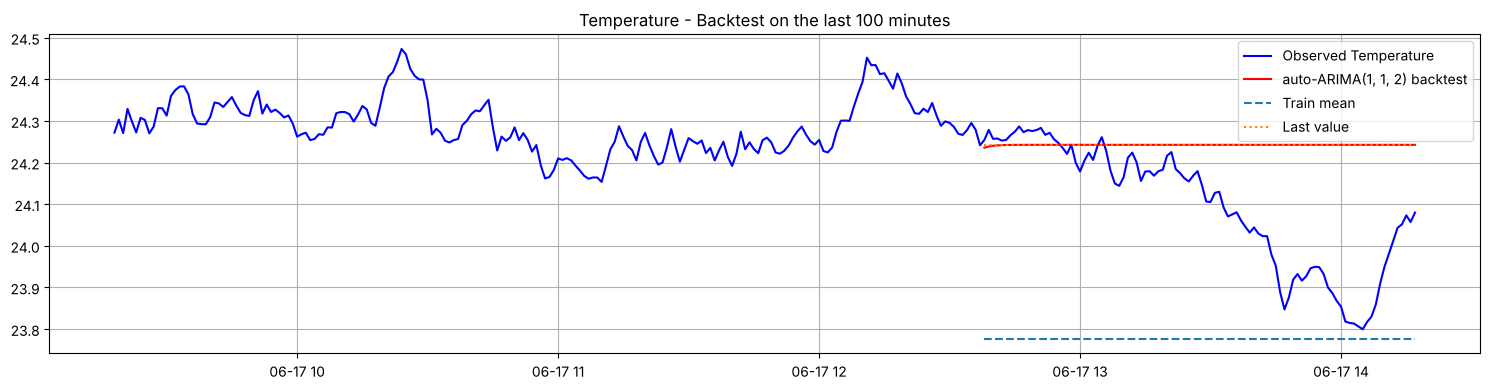

Forecast values that are NaN: 0 of 100


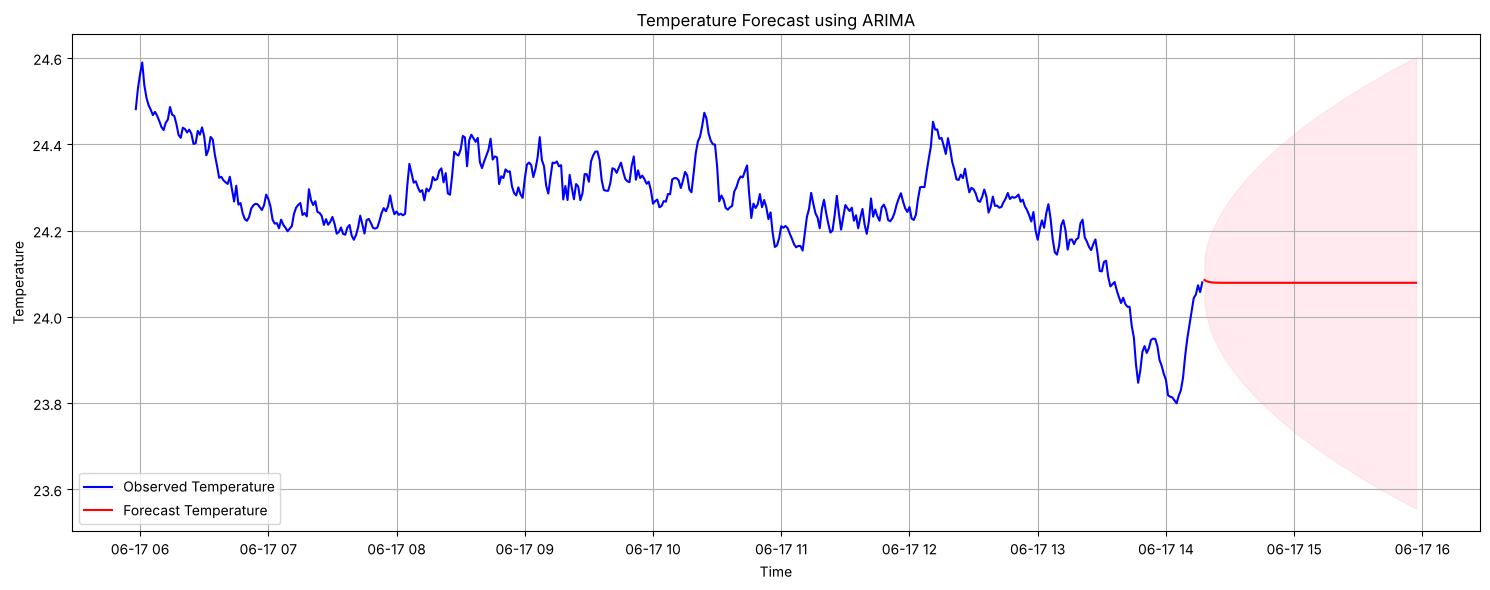

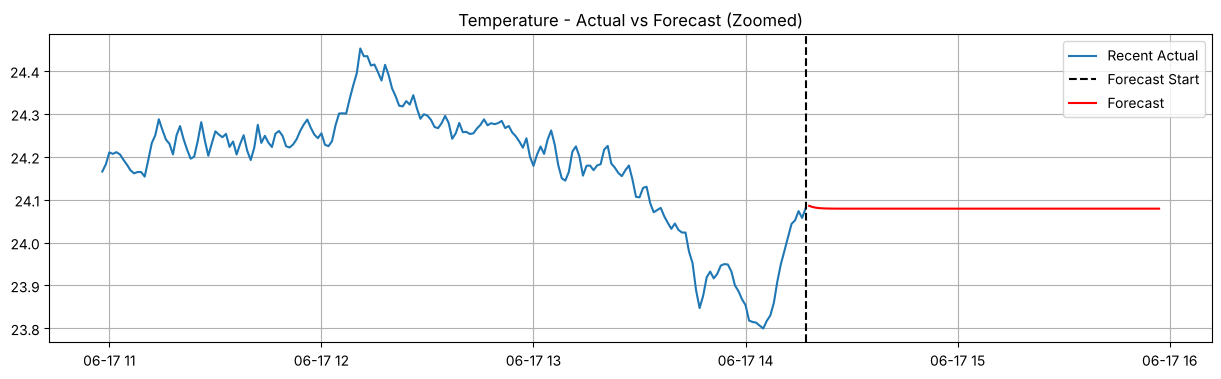

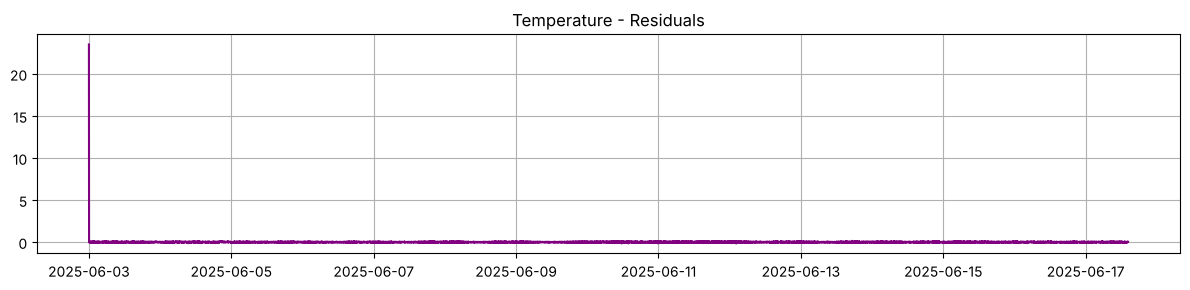

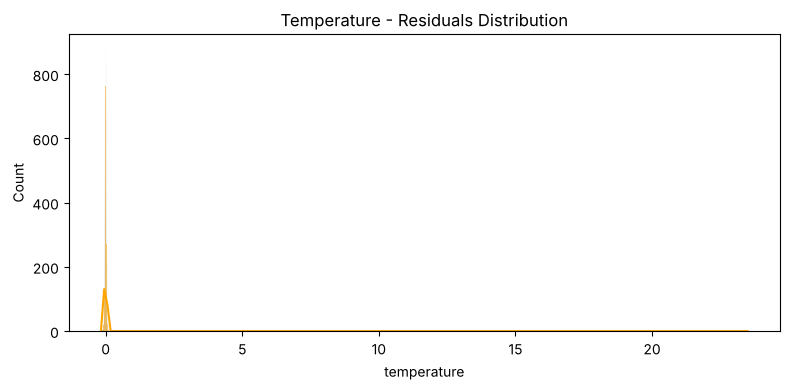

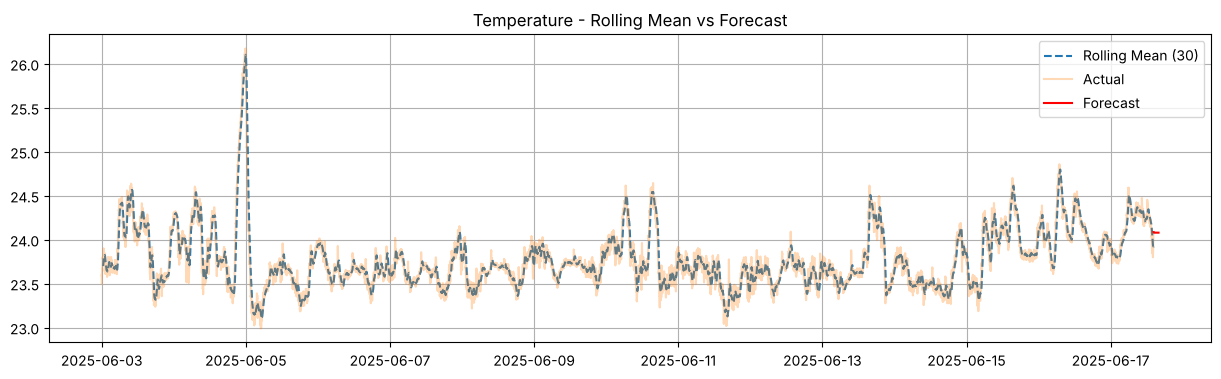

In [4]:
forecast_series(df['temperature'], label='Temperature') # Run forecasting and diagnostics for each variable


Leakage check for Humidity: last train 2025-06-17 12:37:00+00:00 < first test 2025-06-17 12:38:00+00:00: True



ADF Test for Humidity
ADF Statistic: -5.200124441022812
p-value: 8.786941841593179e-06
Critical Value 1%: -3.4306633584618
Critical Value 5%: -2.8616784937452513
Critical Value 10%: -2.566843716381039

Fitting Auto ARIMA for Humidity...
Performing stepwise search to minimize aic


 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=-53839.149, Time=22.64 sec


 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=-51761.985, Time=1.68 sec


 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=-52742.217, Time=0.84 sec


 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=-52702.584, Time=4.21 sec


... (16 outputs left out)

 ARIMA(5,1,0)(0,0,0)[0]             : AIC=-53467.448, Time=1.46 sec


 ARIMA(5,1,2)(0,0,0)[0]             : AIC=-53896.513, Time=15.00 sec


 ARIMA(4,1,2)(0,0,0)[0]             : AIC=-53886.151, Time=10.46 sec


 ARIMA(5,1,1)(0,0,0)[0] intercept   : AIC=-53905.817, Time=27.08 sec

Best model:  ARIMA(5,1,1)(0,0,0)[0]          
Total fit time: 251.899 seconds
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                20918
Model:               SARIMAX(5, 1, 1)   Log Likelihood               26964.199
Date:                Mon, 26 Oct 2026   AIC                         -53914.399
Time:                        18:55:03   BIC                         -53858.761
Sample:                    06-03-2025   HQIC                        -53896.235
                         - 06-17-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.0099      0.007    146.550      0.000       0

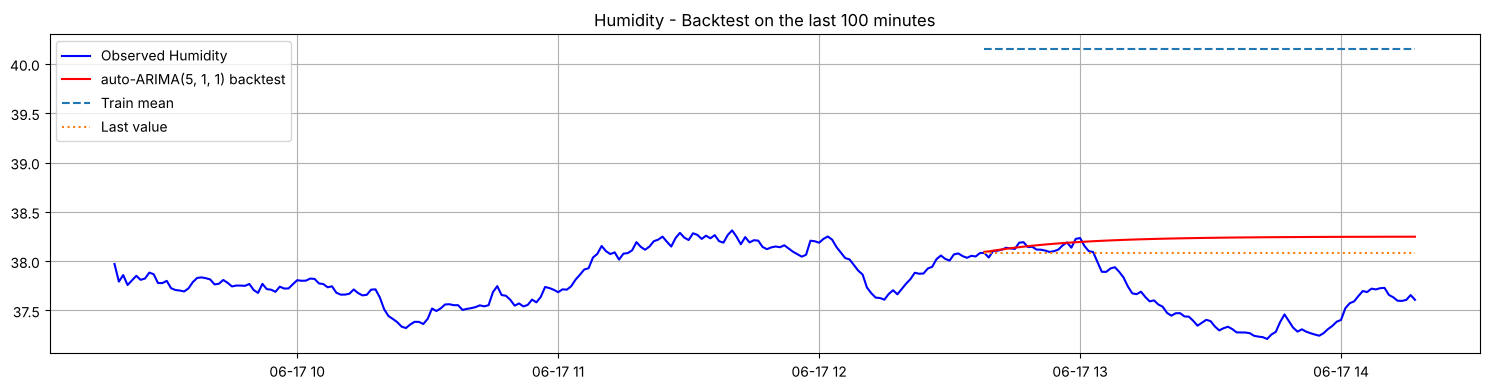

Forecast values that are NaN: 0 of 100


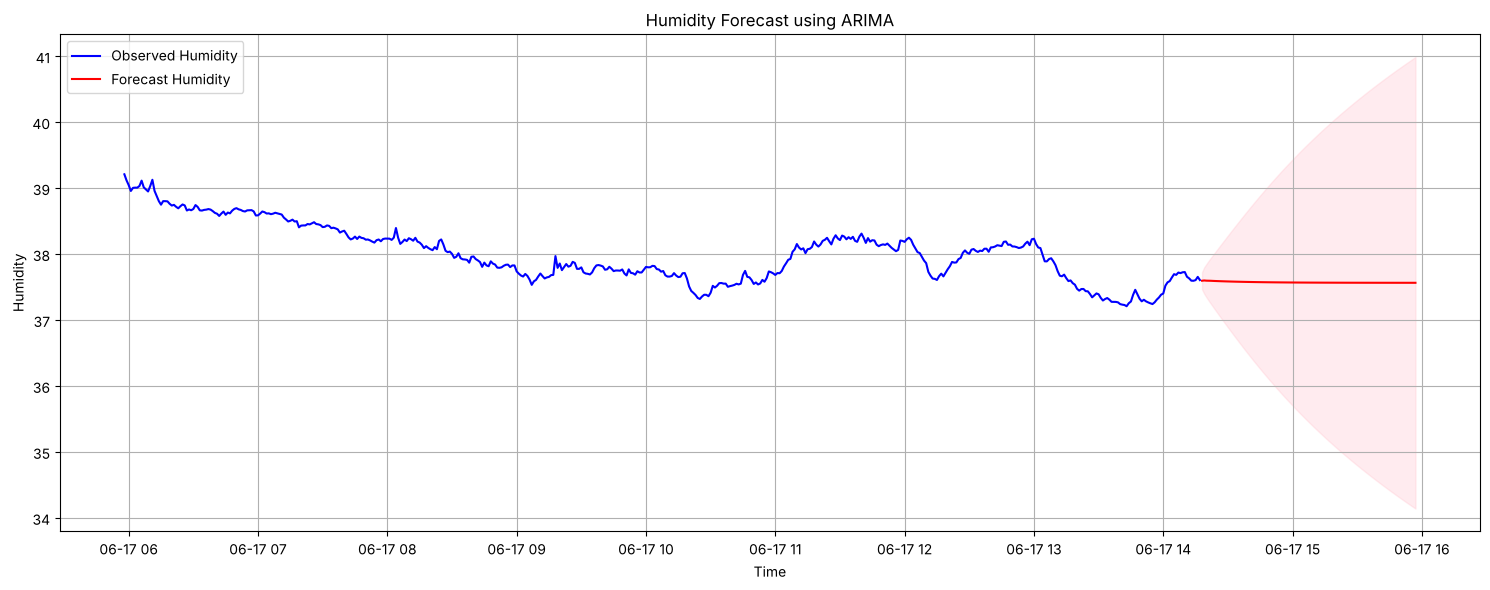

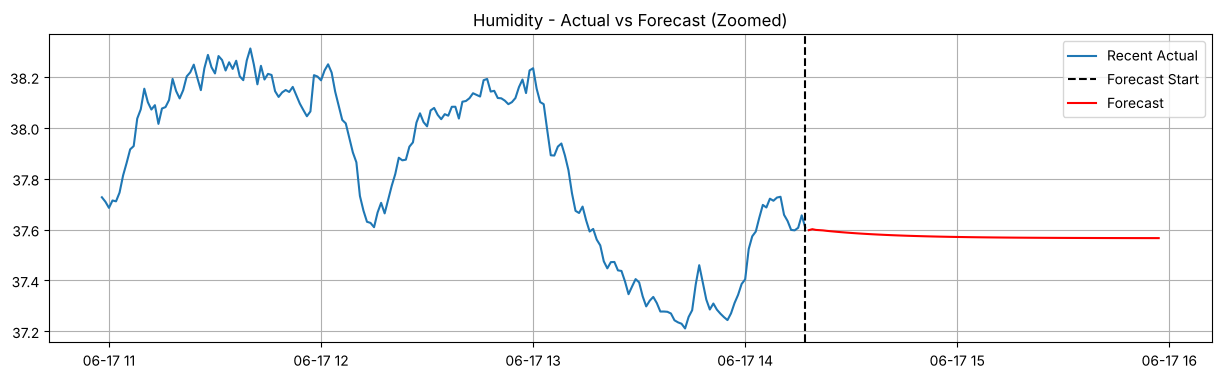

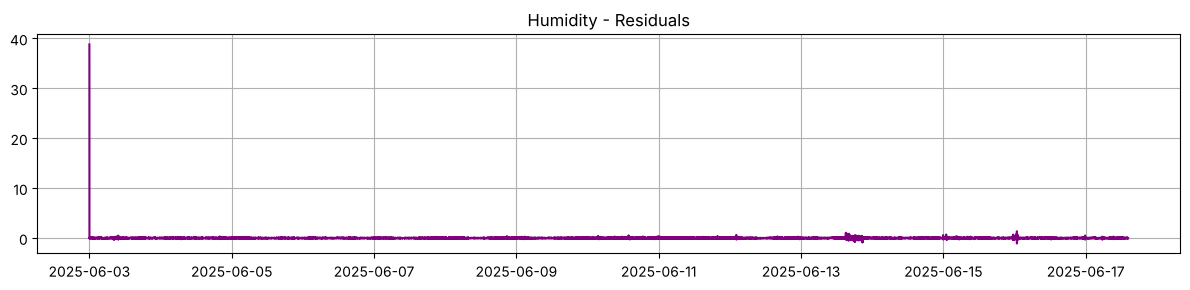

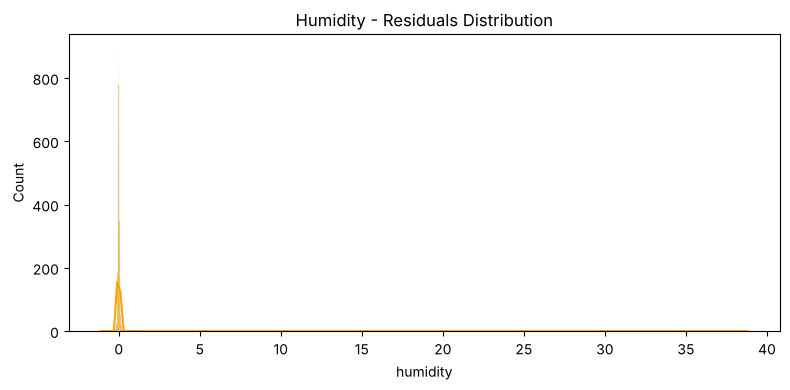

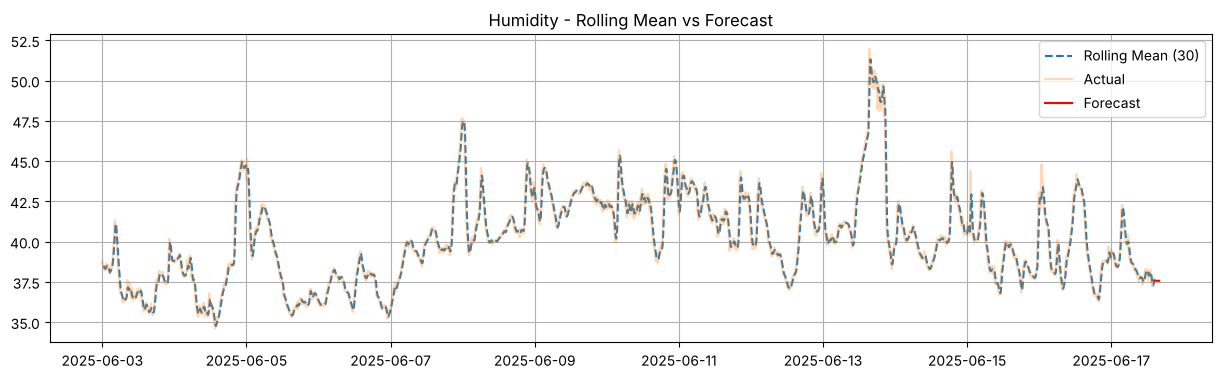

In [5]:
forecast_series(df['humidity'], label='Humidity') # Run forecasting and diagnostics for each variable


Leakage check for VOC: last train 2025-06-17 12:37:00+00:00 < first test 2025-06-17 12:38:00+00:00: True



ADF Test for VOC
ADF Statistic: -7.924879917177128
p-value: 3.6411944565734075e-12
Critical Value 1%: -3.4306631633765248
Critical Value 5%: -2.861678407528766
Critical Value 10%: -2.566843670489604

Fitting Auto ARIMA for VOC...
Performing stepwise search to minimize aic


 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=-85649.784, Time=3.51 sec


 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=-83954.371, Time=1.93 sec


 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=-84869.234, Time=1.36 sec


 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=-85287.886, Time=4.09 sec


... (8 outputs left out)

 ARIMA(1,1,2)(0,0,0)[0]             : AIC=-85656.077, Time=1.02 sec


 ARIMA(0,1,3)(0,0,0)[0]             : AIC=-85656.710, Time=2.65 sec


 ARIMA(1,1,1)(0,0,0)[0]             : AIC=-85600.396, Time=3.75 sec


 ARIMA(1,1,3)(0,0,0)[0]             : AIC=-85654.760, Time=3.75 sec

Best model:  ARIMA(0,1,2)(0,0,0)[0]          
Total fit time: 46.180 seconds
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                20918
Model:               SARIMAX(0, 1, 2)   Log Likelihood               42832.171
Date:                Mon, 26 Oct 2026   AIC                         -85658.342
Time:                        18:56:22   BIC                         -85634.497
Sample:                    06-03-2025   HQIC                        -85650.557
                         - 06-17-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.2597      0.000   -606.887      0.000      -0.2

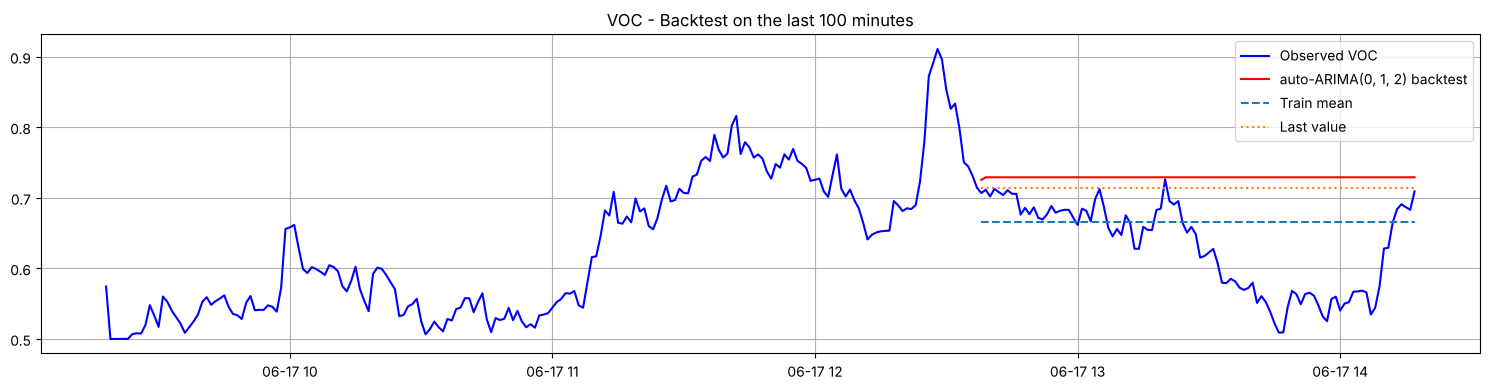

Forecast values that are NaN: 0 of 100


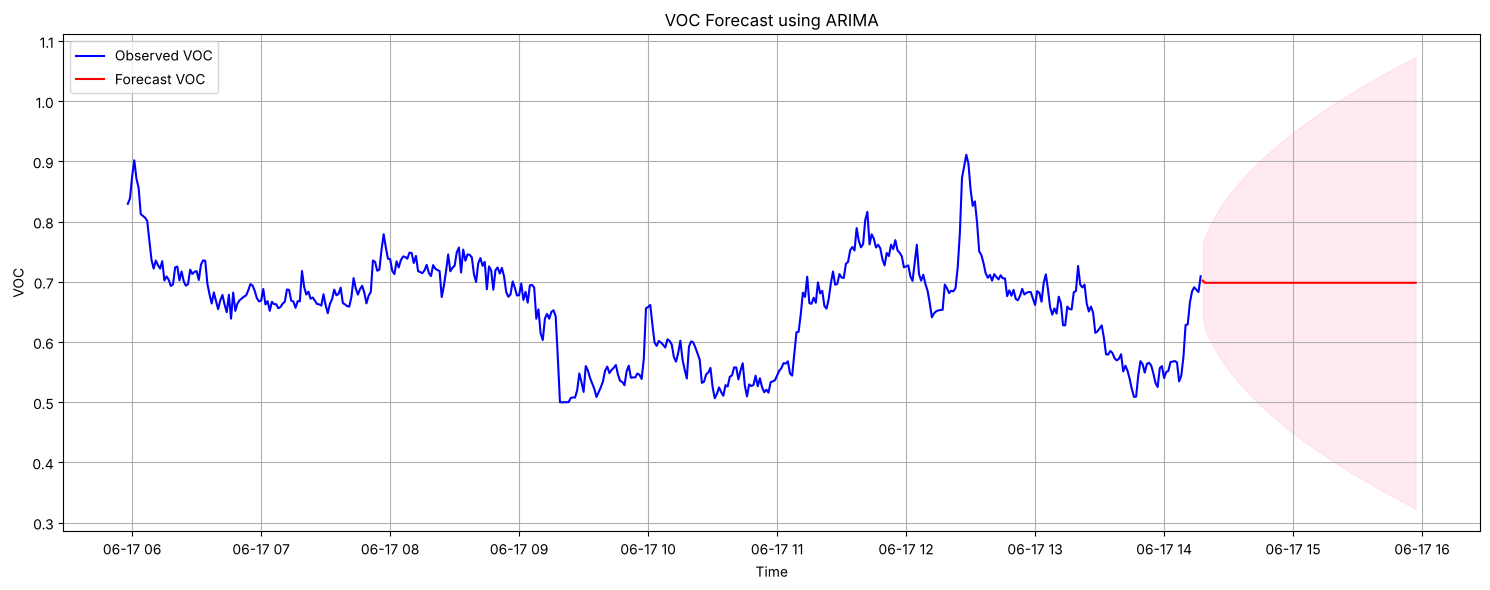

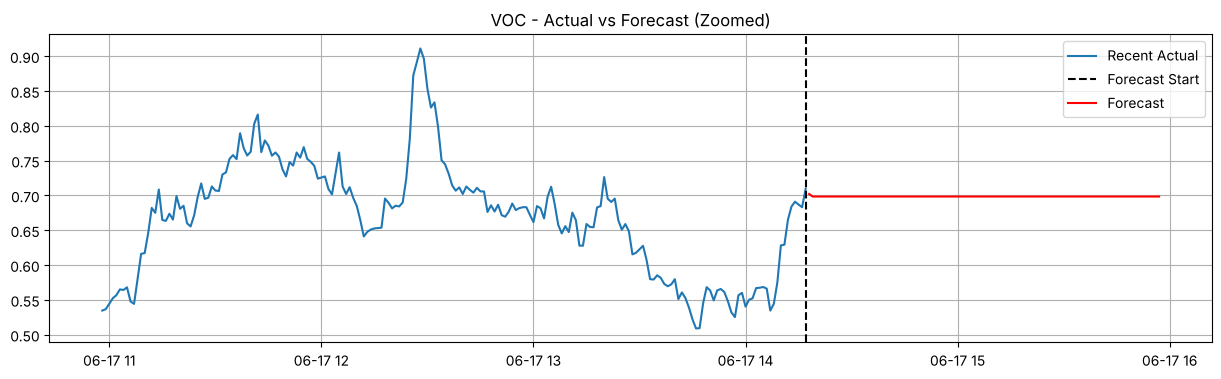

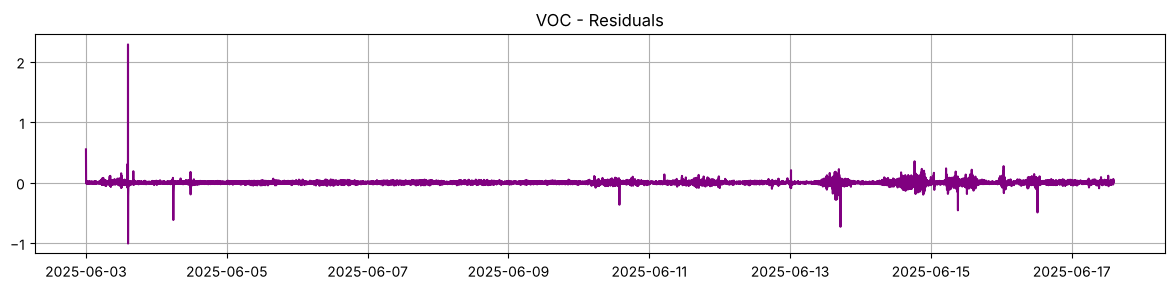

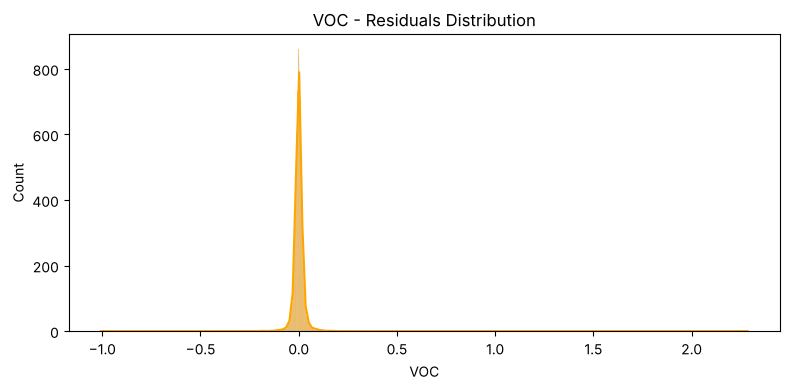

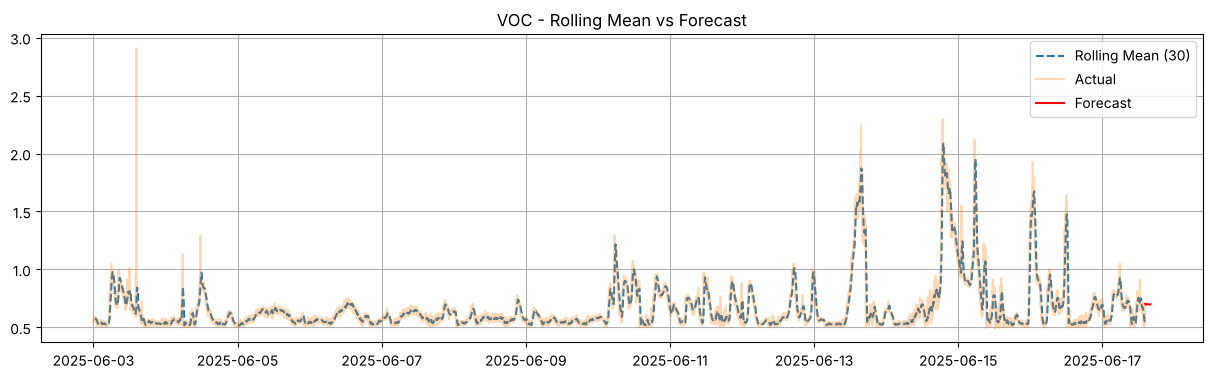

In [6]:
forecast_series(df['VOC'], label='VOC') # Run forecasting and diagnostics for each variable

In [7]:
# --- Summary: auto-ARIMA backtest vs the best naive baseline per sensor ---
summary = pd.DataFrame(summary_rows).set_index("sensor")
print(summary.round(4).to_string())
print("\nLeakage checks: the ARIMA order, the ADF test and the baselines use only the training minutes;")
print("the last 100 minutes are used only for scoring. The future forecast is refit on all minutes and is not scored.")

                 order  ARIMA RMSE  ARIMA MAE             best baseline  baseline RMSE  baseline MAE
sensor                                                                                              
Temperature  (1, 1, 2)      0.2094     0.1574  last value (persistence)         0.2086        0.1567
Humidity     (5, 1, 1)      0.6628     0.5575  last value (persistence)         0.5353        0.4474
VOC          (0, 1, 2)      0.1170     0.0992                train mean         0.0713        0.0558

Leakage checks: the ARIMA order, the ADF test and the baselines use only the training minutes;
the last 100 minutes are used only for scoring. The future forecast is refit on all minutes and is not scored.
